In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Display plots inside the notebook
%matplotlib inline

# Load the SAAR dataset
df = pd.read_csv("DATA/SAAR_elevation.csv")

# Display the first five rows
df.head()

,Name,elevation_m,SAAR_mm,E,N
0,ASK,186,1136,351500,523900
1,OAS,165,889,357910,527500
2,SYH,120,850,358200,522000
3,SLE,212,1166,359300,519200
4,BLA,330,1425,363100,511700


In [2]:
# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (24, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         24 non-null     object
 1   elevation_m  24 non-null     int64 
 2   SAAR_mm      24 non-null     int64 
 3   E            24 non-null     int64 
 4   N            24 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 1.1+ KB

Missing values:
Name           0
elevation_m    0
SAAR_mm        0
E              0
N              0
dtype: int64


In [3]:
# Descriptive statistics for numerical variables

df[['elevation_m', 'SAAR_mm', 'E', 'N']].describe().round(2)

,elevation_m,SAAR_mm,E,N
count,24.00,24.00,24.00,24.00
mean,261.12,1205.67,371312.08,513814.17
std,121.48,369.59,8742.87,8458.73
min,120.00,776.00,351500.00,496300.00
25%,172.50,906.50,366575.00,511200.00
50%,205.00,1126.50,372700.00,514150.00
75%,347.25,1365.75,377350.00,519460.00
max,505.00,2083.00,384500.00,527500.00


In [4]:
# Correlation matrix

correlation_matrix = df[
    ['elevation_m', 'SAAR_mm', 'E', 'N']
].corr()

correlation_matrix.round(3)

,elevation_m,SAAR_mm,E,N
elevation_m,1.000,0.847,0.543,-0.635
SAAR_mm,0.847,1.000,0.388,-0.745
E,0.543,0.388,1.000,-0.516
N,-0.635,-0.745,-0.516,1.000


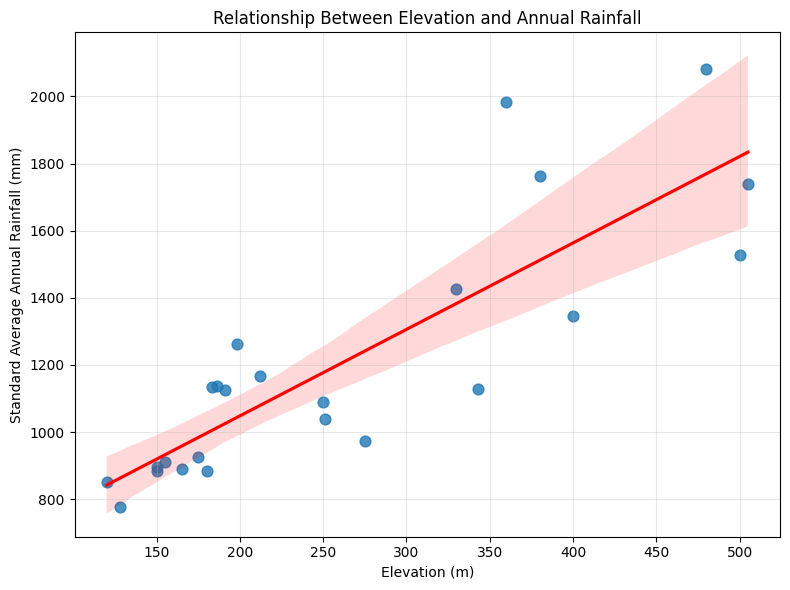

In [5]:
# Scatterplot with regression line

plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='elevation_m',
    y='SAAR_mm',
    ci=95,
    scatter_kws={'s': 60},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Elevation and Annual Rainfall')
plt.xlabel('Elevation (m)')
plt.ylabel('Standard Average Annual Rainfall (mm)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Simple Linear Regression using OLS

# Independent variable (Elevation)
X = df['elevation_m']

# Dependent variable (SAAR)
y = df['SAAR_mm']

# Add intercept to the model
X = sm.add_constant(X)

# Fit the regression model
simple_model = sm.OLS(y, X).fit()

# Display regression results
print(simple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                SAAR_mm   R-squared:                       0.717
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     55.79
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.81e-07
Time:                        10:03:39   Log-Likelihood:                -160.29
No. Observations:                  24   AIC:                             324.6
Df Residuals:                      22   BIC:                             326.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         532.8541     98.979      5.383      

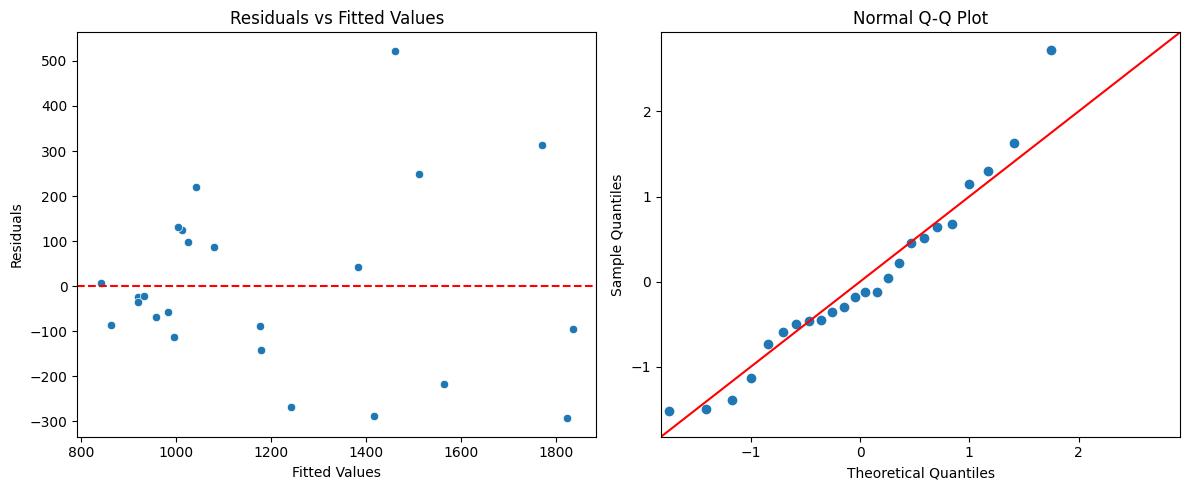

In [7]:
# Calculate fitted values and residuals
fitted_values = simple_model.fittedvalues
residuals = simple_model.resid

# Create diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Residuals vs Fitted Values
sns.scatterplot(x=fitted_values, y=residuals, ax=axes[0])

axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Normal Q-Q Plot
sm.qqplot(residuals, line='45', fit=True, ax=axes[1])
axes[1].set_title('Normal Q-Q Plot')

plt.tight_layout()
plt.show()

In [8]:
# Define the independent variables
X_multiple = df[['elevation_m', 'E', 'N']]

# Define the dependent variable
y = df['SAAR_mm']

# Add the intercept
X_multiple = sm.add_constant(X_multiple)

# Fit the multiple linear regression model
multiple_model = sm.OLS(y, X_multiple).fit()

# Display the regression results
print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                SAAR_mm   R-squared:                       0.815
Model:                            OLS   Adj. R-squared:                  0.787
Method:                 Least Squares   F-statistic:                     29.39
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.58e-07
Time:                        10:03:39   Log-Likelihood:                -155.19
No. Observations:                  24   AIC:                             318.4
Df Residuals:                      20   BIC:                             323.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        1.286e+04   3862.173      3.330      

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select only the independent variables (exclude constant)
X_vif = df[['elevation_m', 'E', 'N']]

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Display results
vif_data.round(3)

,Variable,VIF
0,elevation_m,1.875
1,E,1.524
2,N,1.803


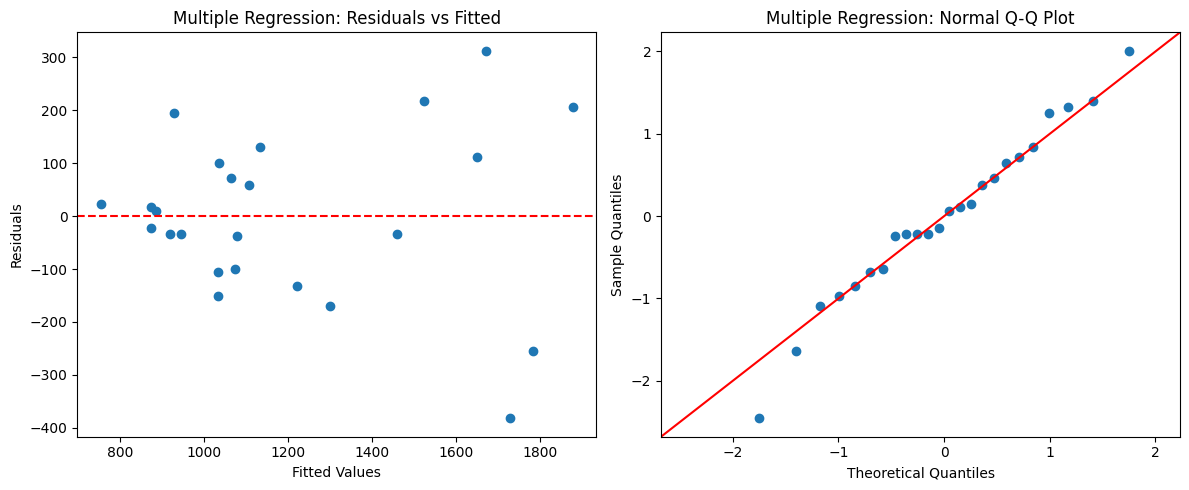

In [10]:
# Calculate fitted values and residuals
fitted_values = multiple_model.fittedvalues
residuals_multiple = multiple_model.resid

# Create diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Residuals vs Fitted Values
axes[0].scatter(fitted_values, residuals_multiple)
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Multiple Regression: Residuals vs Fitted')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Normal Q-Q Plot
sm.qqplot(
    residuals_multiple,
    line='45',
    fit=True,
    ax=axes[1]
)
axes[1].set_title('Multiple Regression: Normal Q-Q Plot')

plt.tight_layout()
plt.show()

In [11]:
# Predict SAAR at the new ungauged location

# Prepare the predictor variables
X_multiple = sm.add_constant(
    df[['elevation_m', 'E', 'N']]
)

# Fit the multiple regression model
multiple_model = sm.OLS(
    df['SAAR_mm'],
    X_multiple
).fit()

# Define the new location
new_location = pd.DataFrame({
    'elevation_m': [400],
    'E': [380000],
    'N': [500000]
})

# Add the intercept
new_location_X = sm.add_constant(
    new_location,
    has_constant='add'
)

# Generate prediction and 95% prediction interval
prediction = multiple_model.get_prediction(
    new_location_X
)

prediction_results = prediction.summary_frame(alpha=0.05)

# Display results
print("SAAR Prediction Results")
print("-----------------------")

print("Predicted SAAR:",
      round(prediction_results['mean'].iloc[0], 2), "mm")

print("95% Prediction Interval:",
      round(prediction_results['obs_ci_lower'].iloc[0], 2),
      "to",
      round(prediction_results['obs_ci_upper'].iloc[0], 2), "mm")

print("\nComplete prediction summary:")
prediction_results

SAAR Prediction Results
-----------------------
Predicted SAAR: 1671.52 mm
95% Prediction Interval: 1288.73 to 2054.3 mm

Complete prediction summary:


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,1671.516161,68.018578,1529.631892,1813.400429,1288.734738,2054.297584


In [12]:
# Check whether the new location is within the observed predictor ranges

print("Observed predictor ranges:")
print(df[['E', 'N', 'elevation_m']].agg(['min', 'max']))

print("\nNew location:")
print(new_location)

print("\nRange checks:")

for column in ['E', 'N', 'elevation_m']:
    value = new_location[column].iloc[0]
    minimum = df[column].min()
    maximum = df[column].max()

    status = "Within range" if minimum <= value <= maximum else "Outside range"

    print(f"{column}: {status} (observed: {minimum} to {maximum})")

Observed predictor ranges:
          E       N  elevation_m
min  351500  496300          120
max  384500  527500          505

New location:
   elevation_m       E       N
0          400  380000  500000

Range checks:
E: Within range (observed: 351500 to 384500)
N: Within range (observed: 496300 to 527500)
elevation_m: Within range (observed: 120 to 505)


In [13]:
from scipy.spatial import Delaunay

# Get the coordinates of the 24 rain gauges
gauge_coordinates = df[['E', 'N']].values

# Create the convex hull
hull = Delaunay(gauge_coordinates)

# Coordinates of the requested prediction location
prediction_location = [[380000, 500000]]

# Check whether the location is inside the convex hull
inside = hull.find_simplex(prediction_location) >= 0

if inside[0]:
    print("The prediction location is INSIDE the convex hull of the rain gauges.")
    print("This supports spatial interpolation.")
else:
    print("The prediction location is OUTSIDE the convex hull of the rain gauges.")
    print("This indicates spatial extrapolation.")

The prediction location is OUTSIDE the convex hull of the rain gauges.
This indicates spatial extrapolation.


In [14]:
import os

# Create the figures folder if it doesn't already exist
os.makedirs("RESULTS/figures", exist_ok=True)

# Check whether the folder exists
print("Figures folder exists:", os.path.exists("RESULTS/figures"))

Figures folder exists: True


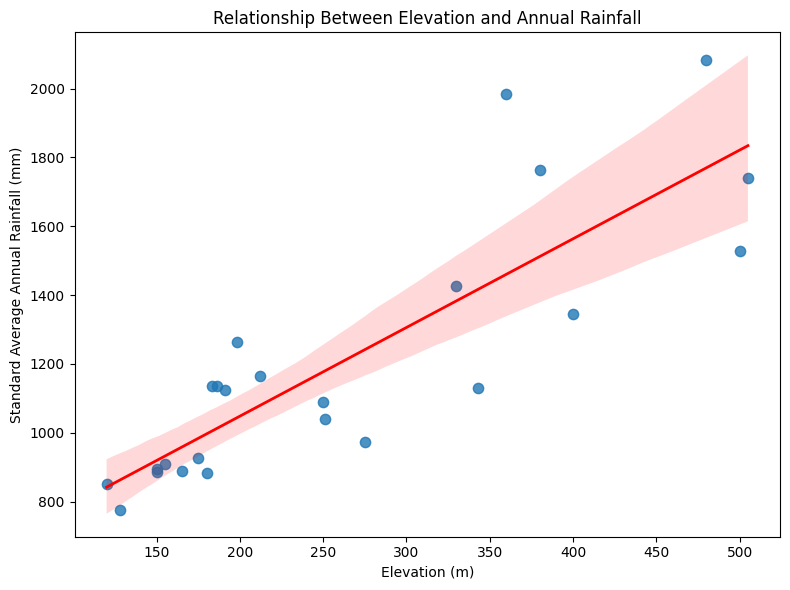

Simple regression graph exported successfully!


In [15]:
# Export the simple linear regression graph

import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='elevation_m',
    y='SAAR_mm',
    ci=95,
    scatter_kws={'s': 55, 'alpha': 0.8},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Relationship Between Elevation and Annual Rainfall')
plt.xlabel('Elevation (m)')
plt.ylabel('Standard Average Annual Rainfall (mm)')

plt.tight_layout()

plt.savefig(
    'RESULTS/figures/simple_regression.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Simple regression graph exported successfully!")

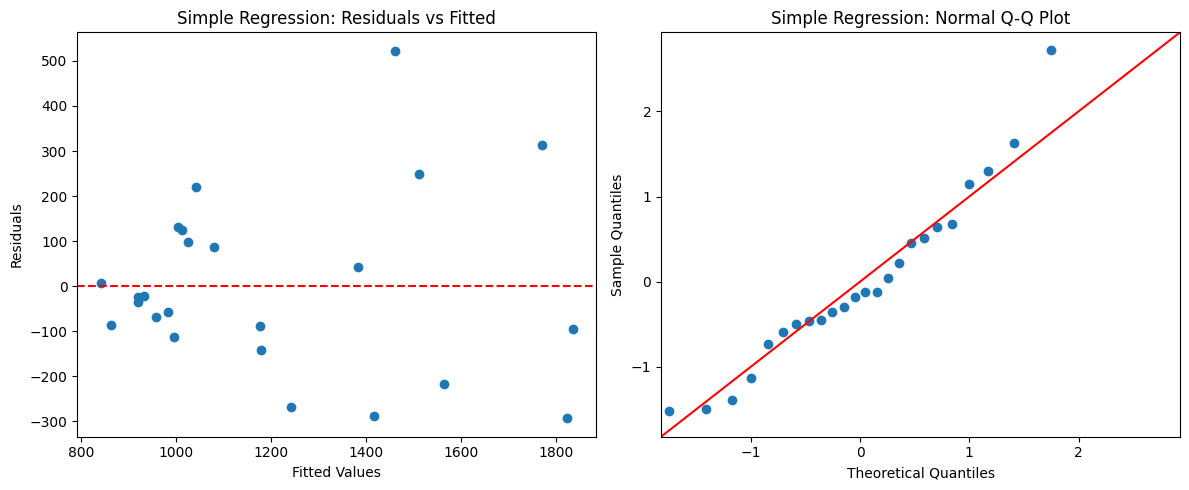

Simple regression diagnostic plots exported successfully!


In [16]:
# Export simple regression diagnostic plots

import statsmodels.api as sm
import matplotlib.pyplot as plt
import os

# Refit the simple linear regression model
X_simple = sm.add_constant(df['elevation_m'])
y = df['SAAR_mm']

simple_model = sm.OLS(y, X_simple).fit()

# Calculate fitted values and residuals
fitted_values = simple_model.fittedvalues
residuals = simple_model.resid

# Create two diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Residuals vs Fitted Values
axes[0].scatter(fitted_values, residuals)
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Simple Regression: Residuals vs Fitted')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Plot 2: Normal Q-Q Plot
sm.qqplot(residuals, line='45', fit=True, ax=axes[1])
axes[1].set_title('Simple Regression: Normal Q-Q Plot')

plt.tight_layout()

# Save the figure
plt.savefig(
    'RESULTS/figures/simple_diagnostics.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Simple regression diagnostic plots exported successfully!")

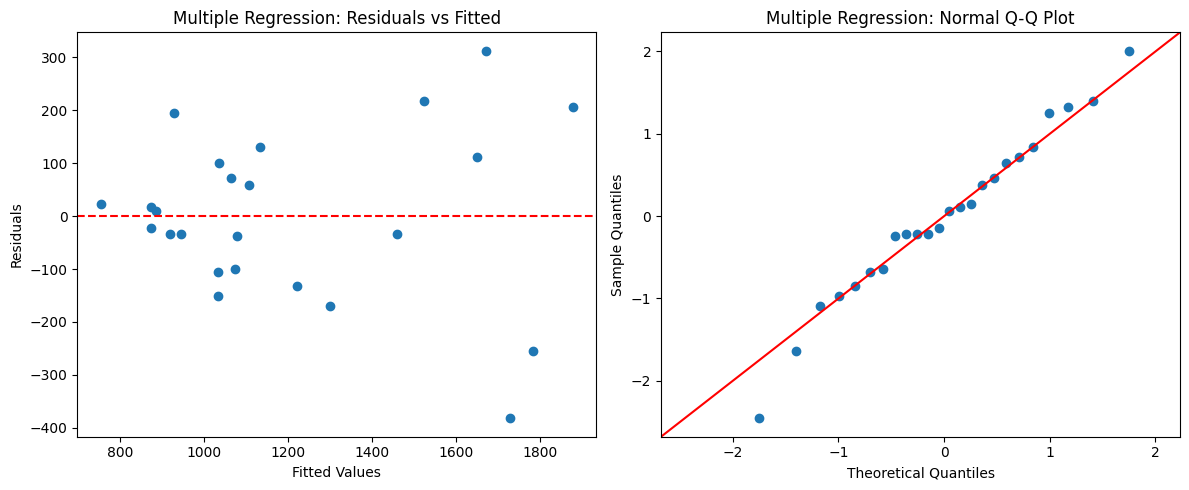

Multiple regression diagnostic plots exported successfully!


In [17]:
# Export multiple regression diagnostic plots

import statsmodels.api as sm
import matplotlib.pyplot as plt

# Define the independent and dependent variables
X_multiple = df[['elevation_m', 'E', 'N']]
X_multiple = sm.add_constant(X_multiple)

y = df['SAAR_mm']

# Fit the multiple regression model
multiple_model = sm.OLS(y, X_multiple).fit()

# Calculate fitted values and residuals
fitted_multiple = multiple_model.fittedvalues
residuals_multiple = multiple_model.resid

# Create diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Residuals vs Fitted
axes[0].scatter(fitted_multiple, residuals_multiple)

axes[0].axhline(
    y=0,
    color='red',
    linestyle='--'
)

axes[0].set_title('Multiple Regression: Residuals vs Fitted')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Plot 2: Normal Q-Q Plot
sm.qqplot(
    residuals_multiple,
    line='45',
    fit=True,
    ax=axes[1]
)

axes[1].set_title('Multiple Regression: Normal Q-Q Plot')

plt.tight_layout()

# Export the figure
plt.savefig(
    'RESULTS/figures/multiple_diagnostics.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Multiple regression diagnostic plots exported successfully!")

In [18]:
# Export regression summaries
with open("RESULTS/regression_summaries.txt", "w") as file:
    file.write("SIMPLE LINEAR REGRESSION\n")
    file.write(str(simple_model.summary()))

    file.write("\n\nMULTIPLE LINEAR REGRESSION\n")
    file.write(str(multiple_model.summary()))

# Export prediction results
prediction_results.to_csv(
    "RESULTS/SAAR_prediction_results.csv",
    index=False
)

# Export VIF results
vif_data.to_csv(
    "RESULTS/multicollinearity_VIF.csv",
    index=False
)

print("Regression summaries, prediction results and VIF results exported.")

Regression summaries, prediction results and VIF results exported.


In [19]:
print(np.sqrt(simple_model.mse_resid))

200.96886957047036
